# Position distribution of the small, quiet events (-82 V, DCRC1pB trigger)

*Draft prepared with Claude Code for A. Villano, 2026-11-02.*

The position of an event on the face from the delays between the 20 % rise times of the channels (`xdel`, `ydel`, `phidel`, `afdel` of `positions-82v-dcrc1pb.ipynb`, after Fritts's `r76_analysis_position_new.c`), for the events that pass two cuts only:

* **`bstd` on all channels**: in every one of the six channels `bstd` (the baseline noise) is below that channel's dotted line of `bstd-distribution-450.ipynb`, twice the median of the random triggers (A 4.10, B 6.15, C 3.20, D 6.31, E 3.37, F 3.54 counts);
* **small**: **no** channel has a pulse height (`current_max`, counts above the baseline) larger than **5 %** of its saturated height (A 1277, B 1095, C 589, D 930, E 680, F 883 counts, from `saturation-over-time.ipynb`; 64, 55, 29, 47, 34 and 44 counts).

Besides those: real triggers (`Unknown`; see `integral-on-the-face.ipynb`), the six 20 % times exist and lie within 60 us of their median (one pulse), and the series `07221113_1159` (low in every channel) is left out. **No cut on the integral** is applied (the earlier notebooks required a total integral above 2, which would remove all of these small pulses).

**The origin and the scale of the plane are set by the large circle of events.** With all six channels small, the plane shows a dense blob and, around it, a larger, roughly circular distribution of events (clearest when the cut on the size is raised to 15 to 30 %, see the zoomed-out scan). The plane is centred on that circle: a circle fitted by eye to its outer edge in the delays with Fritts's offsets has its centre at `xdel` = -1.5 us, `ydel` = +6 us and a radius of about 28 us, so the offsets here are

`xdel = t_E - (t_C + t_D) / 2 + 0.5 us`,  `ydel = 0.866 (t_D - t_C) + 12 us`

(Fritts's are -1 and +9 us) and the detector drawn underneath has the radius of that circle, `R_US` = 28 us. **That the circle is the edge of the face is an assumption**, made to place the drawing; it is not derived. The dense blob of the smallest events then lies at `xdel` of about +22 us, toward the C/D side of the face. (Until 2026-11-02 this notebook used an x offset of -20 us, which put the blob at the origin.)

**The data** are the eight series of `r76-82v-dcrc1pb.dataset.toml`, reprocessed with the baseline window of samples 10 to 450. **The times** are those of `rise_crossing` (`fraction = 0.2`) on the raw traces, not filtered; for pulses this small (tens of counts against a noise of 2 to 3) they are noisy, so the distributions are broader than for large pulses. Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from matplotlib import colors
from matplotlib.patches import Circle, Wedge

from goldpan.dataset import Dataset
from spots_82v import SPOTS

LETTERS = "ABCDEF"
_here = Path.cwd().resolve()
PROCESSING = next(p / "data_analysis" / "R76" / "processing" for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
OUT = Path(Dataset.open(PROCESSING / "r76-82v-dcrc1pb.dataset.toml").spec.output)
manifest = json.loads((OUT / "_goldpan.json").read_text(encoding="utf-8"))
PRE = manifest["streams"]["NAI-S2"]["detector"]["segments"][0]["pretrigger_samples"]
CACHE = Path.home() / "goldsluice-output" / f"relcal-positions-small-82v-p{PRE}.npz"
print(f"{OUT}: baseline window = samples 10 to {PRE}")

def field(tab, k, name):
    # one quantity of one channel: the channel is a struct column of the Parquet file
    return pc.struct_field(tab[f"Side2p{k}"].combine_chunks(), name).to_numpy(zero_copy_only=False)

if CACHE.exists():
    z = np.load(CACHE)
    series, trigger, bstd, height, t = z["series"], z["trigger"], z["bstd"], z["height"], z["t"]
else:
    S_, T_, B_, H_, X_ = [], [], [], [], []
    for f in sorted((OUT / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet")):
        tab = pq.read_table(f, columns=["series", "trigger_type"] + [f"Side2p{k}" for k in LETTERS])
        S_.append(np.asarray(tab["series"].to_pylist())); T_.append(np.asarray(tab["trigger_type"].to_pylist()))
        B_.append(np.column_stack([field(tab, k, "baseline_std") for k in LETTERS]))
        H_.append(np.column_stack([field(tab, k, "current_max") for k in LETTERS]))
        X_.append(np.column_stack([field(tab, k, "crossing_time_s") for k in LETTERS]) * 1e6)       # microseconds
    series, trigger, bstd, height, t = np.concatenate(S_), np.concatenate(T_), np.vstack(B_), np.vstack(H_), np.vstack(X_)
    np.savez(CACHE, series=series, trigger=trigger, bstd=bstd, height=height, t=t)
real, rand = trigger == "Unknown", trigger == "Physics"
print(f"{len(series):,} events in {len(np.unique(series))} series: {real.sum():,} real triggers")

C:\Users\Anthony\goldsluice-output\r76-82v-dcrc1pb: baseline window = samples 10 to 450


1,466,349 events in 8 series: 1,436,655 real triggers


## The cuts

The cut flow, step by step. The `bstd` cut is the dotted line of the `bstd` plots (twice the median of the random triggers of the channel), the same in every channel's own units.

In [2]:
SATH = np.array([1277, 1095, 589, 930, 680, 883.0])         # saturated height of each channel (saturation-over-time.ipynb)
FRAC = 0.05
BSTD_CUT = np.array([2 * np.median(bstd[rand, i]) for i in range(6)])
WINDOW = 60.0                                               # microseconds: the six times of one pulse lie within this of their median
OFFSET_X, OFFSET_Y = 0.5, 12.0                              # Fritts's offsets are -1.0 us in x and +9.0 us in y; these put the centre of the large circle of events at the origin
SPOT_SHIFT = (OFFSET_X - (-1.0), OFFSET_Y - 9.0)            # the spots of spots_82v.py are in delays with Fritts's offsets: move them by this
EXCLUDE = {"07221113_1159"}
print("bstd cut (counts):      " + ", ".join(f"{k} {c:.2f}" for k, c in zip(LETTERS, BSTD_CUT)))
print("5 % of saturation:      " + ", ".join(f"{k} {FRAC * h:.0f}" for k, h in zip(LETTERS, SATH)))

keep = ~np.isin(series, list(EXCLUDE))
bstd_ok = (bstd < BSTD_CUT).all(axis=1)
small = (height < FRAC * SATH).all(axis=1)
finite = np.isfinite(t).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    one_pulse = (np.abs(t - np.nanmedian(t, axis=1, keepdims=True)) < WINDOW).all(axis=1)
steps = [("real triggers", real & keep), ("+ bstd below the cut in all six channels", real & keep & bstd_ok),
         ("+ no channel above 5 % of its saturation", real & keep & bstd_ok & small),
         ("+ six 20 % times", real & keep & bstd_ok & small & finite),
         ("+ one pulse (times within 60 us)", real & keep & bstd_ok & small & finite & one_pulse)]
for name, m in steps:
    print(f"{name:<46}{m.sum():>11,}")
use = steps[-1][1]

xdel = t[:, 4] - 0.5 * (t[:, 2] + t[:, 3]) + OFFSET_X                 # E against the mean of C and D
ydel = 0.866 * (t[:, 3] - t[:, 2]) + OFFSET_Y                         # D against C
afdel = t[:, 5] - t[:, 0]                                             # F against A
phidel = np.degrees(np.arctan2(ydel, xdel))
for name, v in [("xdel", xdel), ("ydel", ydel), ("afdel", afdel)]:
    p = np.percentile(v[use], [1, 16, 50, 84, 99])
    print(f"{name:>6}  1/16/50/84/99 %: " + "  ".join(f"{x:7.2f}" for x in p) + "  (us)")

bstd cut (counts):      A 4.10, B 6.15, C 3.20, D 6.31, E 3.37, F 3.54
5 % of saturation:      A 64, B 55, C 29, D 46, E 34, F 44


real triggers                                   1,292,982
+ bstd below the cut in all six channels        1,088,121
+ no channel above 5 % of its saturation           19,671
+ six 20 % times                                   17,561
+ one pulse (times within 60 us)                   16,228
  xdel  1/16/50/84/99 %:  -26.06    12.93    22.12    32.02    55.29  (us)
  ydel  1/16/50/84/99 %:  -27.06    -5.16     2.22     9.32    30.71  (us)
 afdel  1/16/50/84/99 %:  -39.38   -16.97    -8.82    -1.66    19.66  (us)


## The position distribution

On the left the plane of the delays, with the detector drawn under it as in the earlier notebooks (the `x` axis is reversed so that `C` is upper left, `D` lower left and `E` right; the radius of the face is `R_US` = 28 us, the radius of the large circle of events, an assumption). The red dashed circles are the two high-activity spots found with the large events (`spots_82v.py`): spot C and spot F, 1.5 us radius, moved to the offsets of this notebook. The grey dashed circle is the fitted edge of the large circle of events. Then the azimuth `phidel` and the radius quantity `afdel`.

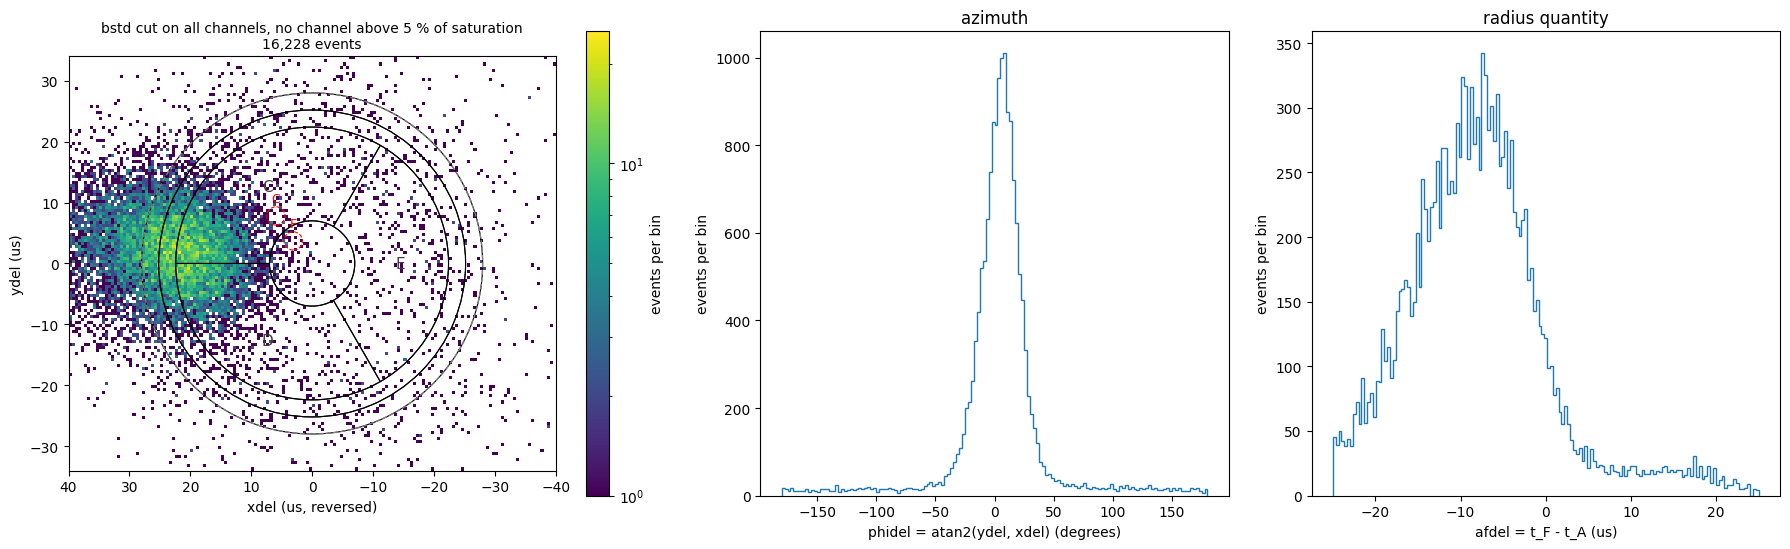

In [3]:
REGIONS = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees, radius 1 = the face
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}
R_US = 28.0       # the radius of the large circle of events (fitted by eye to its outer edge); that it is the edge of the face is an assumption
XR, YR = 40, 34

def draw_detector_mirrored(ax, radius=R_US, label=True, lw=0.8):
    for k, (r_in, r_out, a0, a1) in REGIONS.items():
        ax.add_patch(Wedge((0, 0), r_out * radius, 180 - a1, 180 - a0, width=(r_out - r_in) * radius,
                           facecolor="none", edgecolor="k", linewidth=lw, zorder=3))
        if label and k in "CDE":
            a = np.deg2rad((a0 + a1) / 2)
            ax.text(-0.52 * radius * np.cos(a), 0.52 * radius * np.sin(a), k, ha="center", va="center", fontsize=11, color="0.25", zorder=5)
    ax.set_aspect("equal")

def plane(ax, m, title, spots=False):
    h = ax.hist2d(xdel[m], ydel[m], bins=[160, 136], range=[[-XR, XR], [-YR, YR]], cmap="viridis", norm=colors.LogNorm(), cmin=1, zorder=2)
    draw_detector_mirrored(ax)
    if spots:
        for name, (x0, y0, r) in SPOTS.items():
            x0, y0 = x0 + SPOT_SHIFT[0], y0 + SPOT_SHIFT[1]
            ax.add_patch(Circle((x0, y0), r, fill=False, ec="r", lw=0.8, ls="--", zorder=4))
            ax.text(x0, y0 + r + 0.8, name, color="r", ha="center", fontsize=9, zorder=5)
        ax.add_patch(Circle((0, 0), R_US, fill=False, ec="0.5", lw=1.0, ls="--", zorder=4))
    ax.set_xlim(XR, -XR); ax.set_ylim(-YR, YR)
    ax.set_xlabel("xdel (us, reversed)"); ax.set_ylabel("ydel (us)")
    ax.set_title(f"{title}\n{m.sum():,} events", fontsize=10)
    return h

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
h = plane(axes[0], use, "bstd cut on all channels, no channel above 5 % of saturation", spots=True)
fig.colorbar(h[3], ax=axes[0], label="events per bin")
axes[1].hist(phidel[use], bins=np.linspace(-180, 180, 145), histtype="step", color="C0")
axes[1].set_xlabel("phidel = atan2(ydel, xdel) (degrees)"); axes[1].set_ylabel("events per bin"); axes[1].set_title("azimuth")
axes[2].hist(afdel[use], bins=np.linspace(-25, 25, 150), histtype="step", color="C0")
axes[2].set_xlabel("afdel = t_F - t_A (us)"); axes[2].set_ylabel("events per bin"); axes[2].set_title("radius quantity")
fig.tight_layout()
plt.show()

## What the cuts do to the distribution

The same plane for the events with only the `bstd` cut on all channels, and for the events with only the cut on the size, next to the selection of this notebook, so the effect of each cut can be seen. All three use the same conditions on the times (six 20 % times within 60 us of their median) and real triggers.

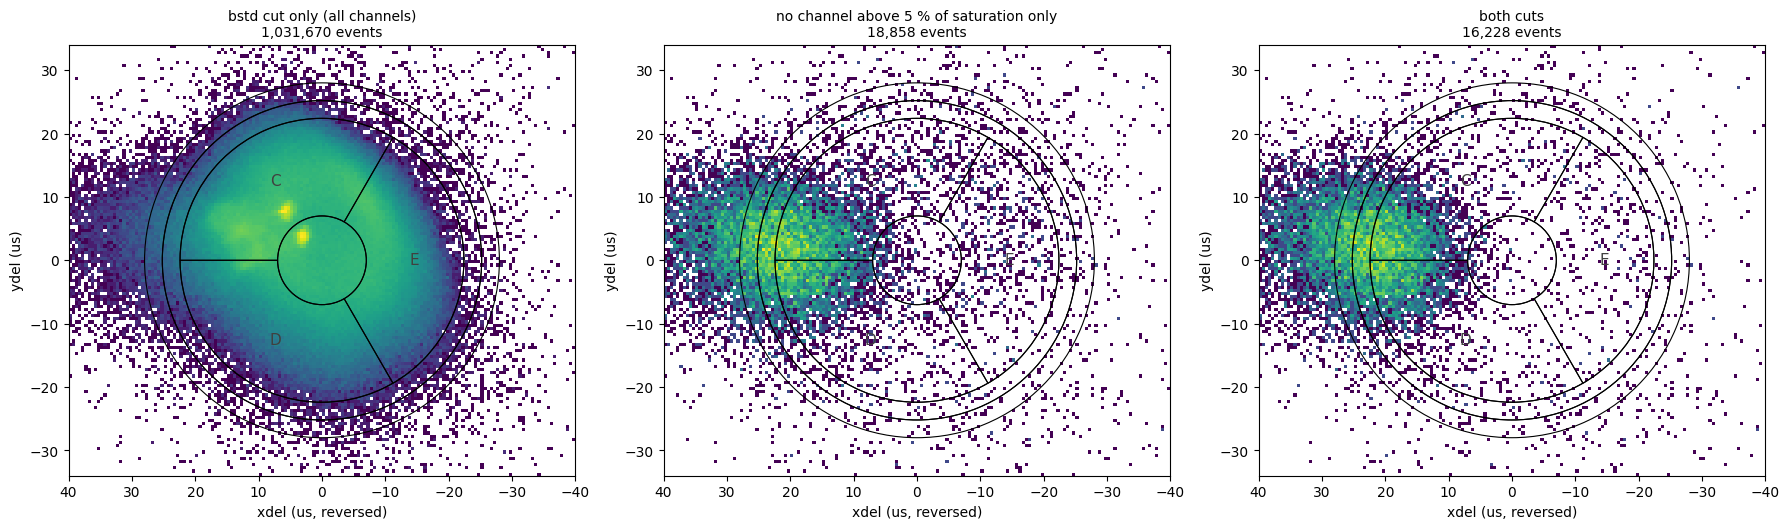

In [4]:
base = real & keep & finite & one_pulse
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
plane(axes[0], base & bstd_ok, "bstd cut only (all channels)")
plane(axes[1], base & small, "no channel above 5 % of saturation only")
plane(axes[2], use, "both cuts")
fig.tight_layout()
plt.show()

## Only events with a visible pulse in every channel

Small, quiet events include some in which a channel has **no pulse at all** (the trigger is the phonon channel Side2pF, so the others may be noise); the 20 % time of such a channel is a time of the noise. The same selection with the extra condition that every channel has a pulse of at least 6 times its `bstd` (height / `bstd` above 6 in all six) shows how much that matters.

events with a pulse above 6 x bstd in every channel: 10,951 of 16,228 (67.5%)
             Side2pA   Side2pB   Side2pC   Side2pD   Side2pE   Side2pF
   visible     89.5%     75.8%     96.6%     92.5%     80.6%     99.6%


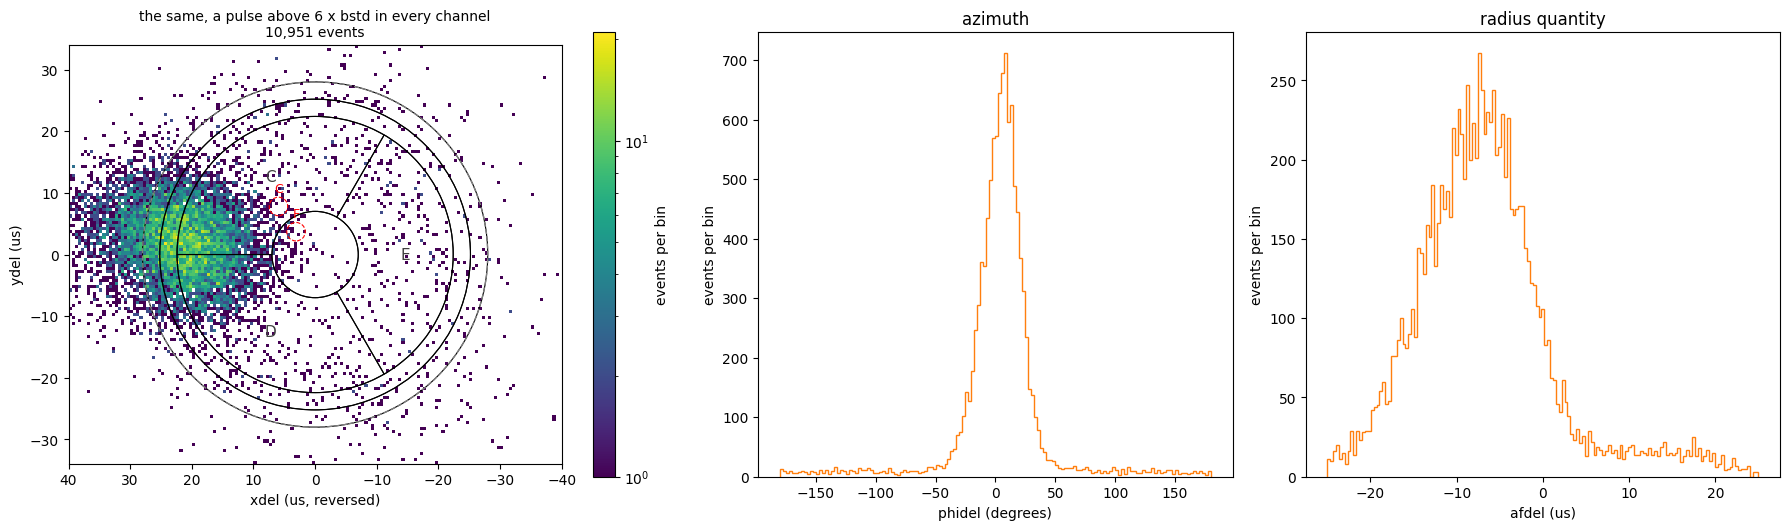

In [5]:
visible = (height > 6 * bstd).all(axis=1)
use_v = use & visible
print(f"events with a pulse above 6 x bstd in every channel: {use_v.sum():,} of {use.sum():,} ({use_v.sum() / use.sum():.1%})")
print(f"{'':>10}" + "".join(f"{'Side2p' + k:>10}" for k in LETTERS))
print(f"{'visible':>10}" + "".join(f"{(height[use, i] > 6 * bstd[use, i]).mean():>10.1%}" for i in range(6)))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
h = plane(axes[0], use_v, "the same, a pulse above 6 x bstd in every channel", spots=True)
fig.colorbar(h[3], ax=axes[0], label="events per bin")
axes[1].hist(phidel[use_v], bins=np.linspace(-180, 180, 145), histtype="step", color="C1")
axes[1].set_xlabel("phidel (degrees)"); axes[1].set_ylabel("events per bin"); axes[1].set_title("azimuth")
axes[2].hist(afdel[use_v], bins=np.linspace(-25, 25, 150), histtype="step", color="C1")
axes[2].set_xlabel("afdel (us)"); axes[2].set_ylabel("events per bin"); axes[2].set_title("radius quantity")
fig.tight_layout()
plt.show()

## A scan in the maximum pulse height, from about 0 to 30 %

The same plots, as a movie, with the cut on the size not fixed at 5 % of the saturated height but **scanned**: in every frame, no channel has a pulse height above a fraction `f` of its saturated height, with `f` from 0.5 % to 30 % (0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25 and 30 %). The other conditions are those of the notebook (real triggers, `bstd` below the cut in every channel, the six 20 % times within 60 us of their median, the offsets that centre the large circle). The selections are nested: an event in one frame is in all later ones. The colour scale is the same in all frames (events per bin), so the density grows from frame to frame; the two histograms have fixed axes. Saved as `figures/position-small-vs-height-max.gif`.

     f    events  xdel median  ydel median
  0.5%         0          nan          nan
  1.0%        11         2.69         6.03
  1.5%        37        -6.37        13.45
  2.0%        52        -0.38        12.62
  3.0%     3,618        25.98         2.10
  4.0%    10,183        23.60         2.13
  5.0%    16,228        22.12         2.22
  6.0%    21,774        20.91         2.29
  8.0%    30,633        19.42         2.35
 10.0%    37,015        18.61         2.42
 12.0%    42,118        18.06         2.49
 15.0%    48,191        17.46         2.56
 20.0%    56,619        16.62         2.63
 25.0%    65,311        15.75         2.65
 30.0%    75,284        14.86         2.65


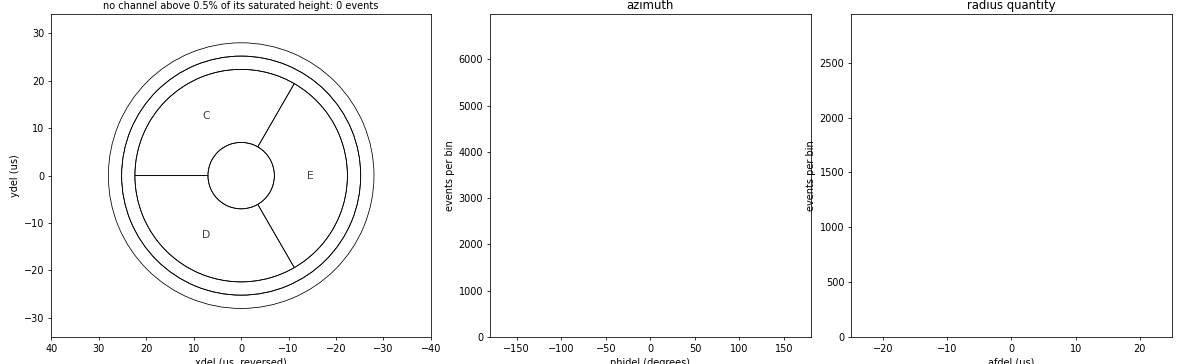

In [6]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

FRACS = [0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30]
common = real & keep & bstd_ok & finite & one_pulse
sets = [common & (height < f * SATH).all(axis=1) for f in FRACS]
print(f"{'f':>6} {'events':>9} {'xdel median':>12} {'ydel median':>12}")
for f, m in zip(FRACS, sets):
    med = (np.median(xdel[m]), np.median(ydel[m])) if m.sum() else (np.nan, np.nan)
    print(f"{f:>6.1%} {m.sum():>9,} {med[0]:>12.2f} {med[1]:>12.2f}")

xe = np.linspace(-XR, XR, 161); ye = np.linspace(-YR, YR, 137)
counts = [np.histogram2d(xdel[m], ydel[m], bins=[xe, ye])[0] for m in sets]
vmax = max(c.max() for c in counts)
pbins = np.linspace(-180, 180, 73); abins = np.linspace(-25, 25, 76)
pmax = max(np.histogram(phidel[m], bins=pbins)[0].max() for m in sets)
amax = max(np.histogram(afdel[m], bins=abins)[0].max() for m in sets)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
def frame(k):
    f, m, c = FRACS[k], sets[k], counts[k]
    for ax in axes:
        ax.clear()
    ax = axes[0]
    ax.pcolormesh(xe, ye, np.where(c > 0, c, np.nan).T, cmap="viridis", norm=colors.LogNorm(vmin=1, vmax=vmax), zorder=2)
    draw_detector_mirrored(ax)
    ax.set_xlim(XR, -XR); ax.set_ylim(-YR, YR)
    ax.set_xlabel("xdel (us, reversed)"); ax.set_ylabel("ydel (us)")
    ax.set_title(f"no channel above {f:.1%} of its saturated height: {m.sum():,} events", fontsize=10)
    axes[1].hist(phidel[m], bins=pbins, histtype="step", color="C0")
    axes[1].set_xlim(-180, 180); axes[1].set_ylim(0, 1.05 * pmax)
    axes[1].set_xlabel("phidel (degrees)"); axes[1].set_ylabel("events per bin"); axes[1].set_title("azimuth")
    axes[2].hist(afdel[m], bins=abins, histtype="step", color="C0")
    axes[2].set_xlim(-25, 25); axes[2].set_ylim(0, 1.05 * amax)
    axes[2].set_xlabel("afdel (us)"); axes[2].set_ylabel("events per bin"); axes[2].set_title("radius quantity")
    return []

fig.tight_layout()
anim = FuncAnimation(fig, frame, frames=len(FRACS), interval=900, blit=False)
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
GIF = FIG_DIR / "position-small-vs-height-max.gif"
anim.save(GIF, writer=PillowWriter(fps=1.1), dpi=70)
plt.close(fig)
Image(filename=str(GIF))

### The same scan, zoomed way out

The same 15 selections and the same colour scale, but the plane of the delays drawn over +-80 us in `xdel` and +-60 us in `ydel` (the face is the small drawing in the middle), to see where the events that lie far from it go as the cut on the height is raised. Saved as `figures/position-small-vs-height-max-wide.gif`. The counts printed are the events inside this wider view.

     f  in the view        of
  0.5%            0         0
  1.0%           11        11
  1.5%           34        37
  2.0%           49        52
  3.0%        3,613     3,618
  4.0%       10,176    10,183
  5.0%       16,219    16,228
  6.0%       21,763    21,774
  8.0%       30,621    30,633
 10.0%       37,003    37,015
 12.0%       42,106    42,118
 15.0%       48,179    48,191
 20.0%       56,606    56,619
 25.0%       65,298    65,311
 30.0%       75,271    75,284


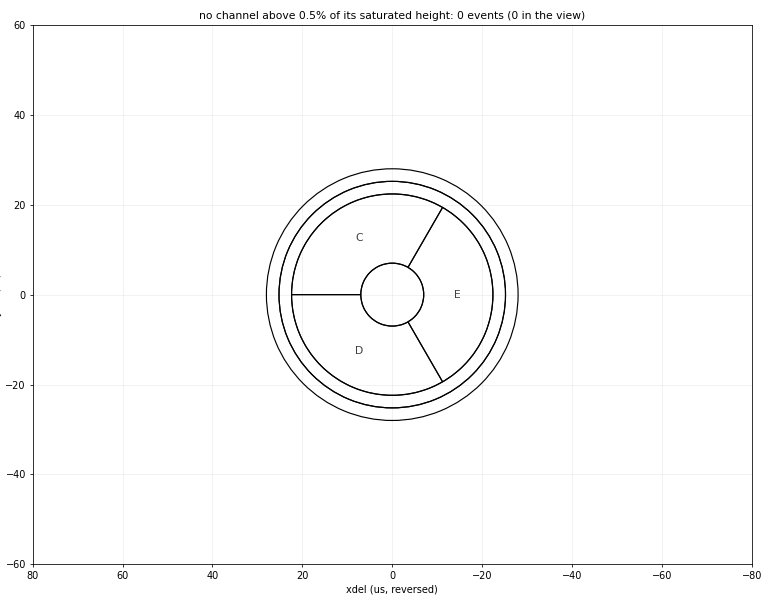

In [7]:
XW, YW = 80, 60
xw = np.linspace(-XW, XW, 201); yw = np.linspace(-YW, YW, 151)
wide = [np.histogram2d(xdel[m], ydel[m], bins=[xw, yw])[0] for m in sets]
vmax_w = max(c.max() for c in wide)
print(f"{'f':>6} {'in the view':>12} {'of':>9}")
for f, m, c in zip(FRACS, sets, wide):
    print(f"{f:>6.1%} {int(c.sum()):>12,} {m.sum():>9,}")

fig, ax = plt.subplots(figsize=(11, 8.6))
def frame_wide(k):
    f, m, c = FRACS[k], sets[k], wide[k]
    ax.clear()
    ax.pcolormesh(xw, yw, np.where(c > 0, c, np.nan).T, cmap="viridis", norm=colors.LogNorm(vmin=1, vmax=vmax_w), zorder=2)
    draw_detector_mirrored(ax, lw=1.2)
    ax.set_xlim(XW, -XW); ax.set_ylim(-YW, YW)
    ax.set_xlabel("xdel (us, reversed)"); ax.set_ylabel("ydel (us)")
    ax.set_title(f"no channel above {f:.1%} of its saturated height: {m.sum():,} events ({int(c.sum()):,} in the view)", fontsize=11)
    ax.grid(alpha=0.2)
    return []

fig.tight_layout()
anim_w = FuncAnimation(fig, frame_wide, frames=len(FRACS), interval=900, blit=False)
GIF_W = FIG_DIR / "position-small-vs-height-max-wide.gif"
anim_w.save(GIF_W, writer=PillowWriter(fps=1.1), dpi=70)
plt.close(fig)
Image(filename=str(GIF_W))

## The left-hand blob, and its Side2pF integrals

The small, quiet events of this notebook (the selection `use`: both cuts, six 20 % times within 60 us) are concentrated in a blob on the left of the face, near the C/D boundary. Its densest point and its median are at about `xdel` = +22 us, `ydel` = +2 us; the density around that point halves at about 7 us and falls to a quarter at about 10 us. The cut on the blob is a circle of radius `BLOB_R` = 10 us around (`BLOB_X`, `BLOB_Y`) = (22, 2) us; the rest of the small events (`use` outside the circle) are the comparison.

The integral is not in the cache of the first cell, so the Side2pF `integral` (and the other channels', for later) is read once from the same Parquet files, in the same order, into a second cache next to the first.

small, quiet events: 16,228; in the blob: 8,888 (55%); outside it: 7,340
              blob: Side2pF integral 10/50/90 %: -0.0366  -0.0072  0.0012 ADC counts x s;  Side2pF height median 31 counts
  outside the blob: Side2pF integral 10/50/90 %: -0.0510  -0.0105  0.0009 ADC counts x s;  Side2pF height median 25 counts


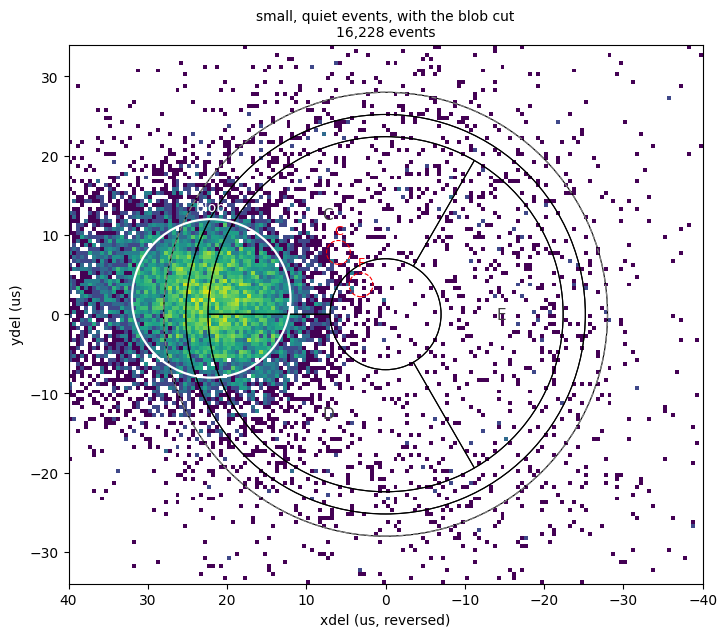

In [8]:
BLOB_X, BLOB_Y, BLOB_R = 22.0, 2.0, 10.0                    # us, in the offsets of this notebook

ICACHE = CACHE.with_name(CACHE.stem + "-integral.npz")
if ICACHE.exists():
    integral = np.load(ICACHE)["integral"]
else:
    integral = np.vstack([np.column_stack([field(pq.read_table(f, columns=[f"Side2p{k}" for k in LETTERS]), k, "integral") for k in LETTERS])
                          for f in sorted((OUT / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))])
    np.savez(ICACHE, integral=integral)
assert len(integral) == len(series), "the integral cache does not match the event cache: delete both and rerun"

in_blob = np.hypot(xdel - BLOB_X, ydel - BLOB_Y) < BLOB_R
blob, rest = use & in_blob, use & ~in_blob
IF = integral[:, LETTERS.index("F")]
print(f"small, quiet events: {use.sum():,}; in the blob: {blob.sum():,} ({blob.sum() / use.sum():.0%}); outside it: {rest.sum():,}")
for name, m in (("blob", blob), ("outside the blob", rest)):
    p = np.percentile(IF[m], [10, 50, 90])
    print(f"{name:>18}: Side2pF integral 10/50/90 %: " + "  ".join(f"{v:.4f}" for v in p) + " ADC counts x s;"
          f"  Side2pF height median {np.median(height[m, LETTERS.index('F')]):.0f} counts")

fig, ax = plt.subplots(figsize=(8.5, 7))
plane(ax, use, "small, quiet events, with the blob cut", spots=True)
ax.add_patch(Circle((BLOB_X, BLOB_Y), BLOB_R, fill=False, ec="w", lw=1.6, zorder=6))
ax.text(BLOB_X, BLOB_Y + BLOB_R + 1, "blob", color="w", ha="center", fontsize=10, zorder=7)
plt.show()

### The Side2pF integral of the blob

The distribution of the Side2pF `integral` (ADC counts x s) of the events in the blob, against the small, quiet events outside it, each normalised to its number of events, on a linear and a log scale. For scale: these pulses are below 5 % of saturation in every channel (Side2pF below 44 counts), so their integrals are small, around 0.01 to 0.05; the random triggers' integrals spread by about 0.1 (from the slow drift of the baseline), which is why the distribution reaches below zero.

**What the integral measures here.** Nearly all of these integrals are negative or near zero, the blob's and the others' alike, and so are the random triggers'. A few raw traces of the blob (looked at while writing this section) show why: the pulses are real, 20 to 40 counts high and back to the baseline in about 200 us, but the baseline then drifts **down** by 5 to 40 counts over the 3 ms of the trace. The integral runs over the whole trace, so a pulse worth about +0.005 ADC counts x s is outweighed by a drift worth -0.01 to -0.05. **For events this small the whole-trace integral measures the drift, not the pulse**; the Side2pF height is shown below as well, and an integral over a short window after the trigger (not in the processed data yet) would be the better measure.

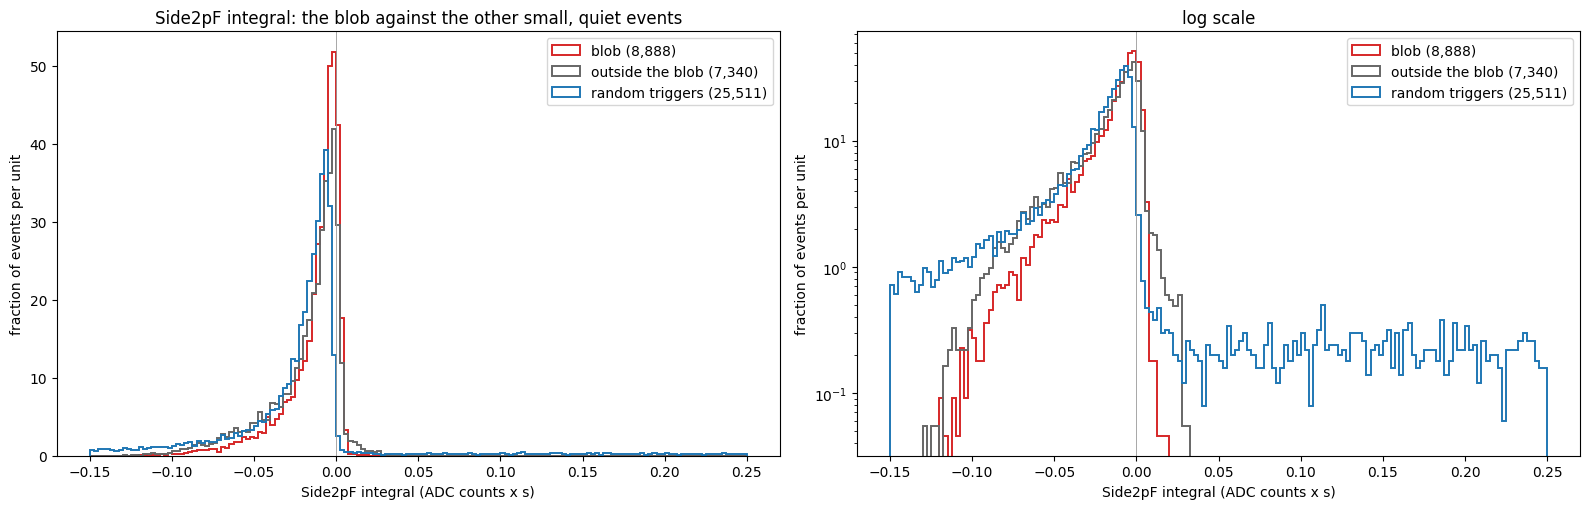

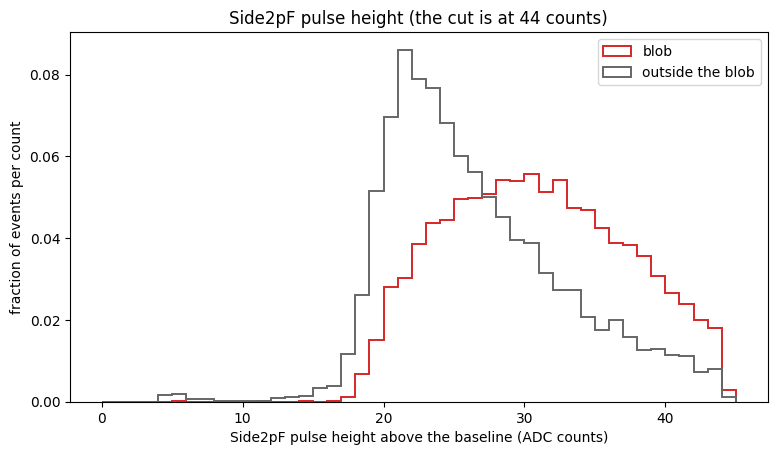

In [9]:
BINS_I = np.linspace(-0.15, 0.25, 161)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, log in zip(axes, (False, True)):
    for m, c, lab in ((blob, "C3", f"blob ({blob.sum():,})"), (rest, "0.4", f"outside the blob ({rest.sum():,})"),
                      (rand & keep, "C0", f"random triggers ({(rand & keep).sum():,})")):
        ax.hist(IF[m], bins=BINS_I, histtype="step", density=True, color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("Side2pF integral (ADC counts x s)")
    ax.set_ylabel("fraction of events per unit")
    if log:
        ax.set_yscale("log")
    ax.set_title("log scale" if log else "Side2pF integral: the blob against the other small, quiet events")
    ax.legend()
fig.tight_layout()
plt.show()

# the same events by their Side2pF pulse height, which the drift of the baseline does not reach
fig, ax = plt.subplots(figsize=(9, 4.8))
for m, col, lab in ((blob, "C3", "blob"), (rest, "0.4", "outside the blob")):
    ax.hist(height[m, LETTERS.index("F")], bins=np.arange(0, 46, 1), histtype="step", density=True, color=col, linewidth=1.4, label=lab)
ax.set_xlabel("Side2pF pulse height above the baseline (ADC counts)")
ax.set_ylabel("fraction of events per count")
ax.set_title("Side2pF pulse height (the cut is at 44 counts)")
ax.legend()
plt.show()

### A short-window integral, with the drift fitted and subtracted, and the pulses filtered

The integral over a short window after the trigger instead of the whole trace, so that the slow drift of the baseline hardly enters: samples `WIN` = 480 to 1125 (from 16 us before the trigger to 500 us after it; the small pulses are back to the baseline in about 200 us), times the sample period. None of this is in the processed data, so it is computed here from the raw dumps in `~/idx`, for every channel, for the small, quiet events (`use`) and the random triggers, and cached (`...-window480-1125-line-lp50k.npz`). Reading the dumps takes about 15 minutes the first time. Three quantities per channel:

* **`integral_w`**: the window integral with the baseline of `integral` (the mean of samples 10 to 450);
* **`integral_wl`**: the window integral after a **straight line is fitted and subtracted**: the line is fitted to the pretrigger samples (10 to 450) **and** to the late tail (from 1.5 ms after the trigger to the end of the trace), leaving the pulse out, so it follows the drift under the pulse (the two-sided baseline of `pulse-normalization/small_triggers.py`, here of order 1);
* **`height_fl`**: the pulse height after the same line is subtracted and the trace is **low-pass filtered** (`goldpan.algorithms.lowpass`, 50 kHz, zero phase): the largest value in the window. The filter lowers the noise of the height (2 to 6 counts per sample) and hardly changes a pulse that lasts 200 us; it does not change the integral (it keeps the mean).

The trigger is at sample 500 (the pulses start there; the baseline window of this reprocessing ends at 450).

In [10]:
from goldpan.adapters import idx
from goldpan.algorithms import lowpass
from goldpan.config import PulseConfig
import goldpan.channels as pch

WIN = (480, 1125)
TRIG, TAIL_FROM = 500, 500 + int(1500 / 0.8)           # samples: the trigger, and the start of the late tail (1.5 ms after it)
CUTOFF_HZ = 50e3
WCACHE = CACHE.with_name(CACHE.stem + f"-window{WIN[0]}-{WIN[1]}-line-lp{CUTOFF_HZ / 1e3:.0f}k.npz")
wanted = use | (rand & keep)
cfg = PulseConfig(pretrigger_samples=PRE, glitch_samples=10, sample_period_s=0.8e-6)

def line_fit(x):
    """The straight line fitted to samples 10..PRE and TAIL_FROM..end of every trace in `x` (n, samples), at every sample."""
    n = x.shape[-1]
    s = np.r_[np.arange(10, PRE), np.arange(TAIL_FROM, n)]
    slope, icpt = np.polyfit(s, x[:, s].T, 1)
    return slope[:, None] * np.arange(n) + icpt[:, None]

if WCACHE.exists():
    z = np.load(WCACHE)
    assert len(z["integral_w"]) == len(series), "the window cache does not match the event cache: delete it and rerun"
    integral_w, integral_wl, height_fl = z["integral_w"], z["integral_wl"], z["height_fl"]
else:
    SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
    files = sorted((OUT / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))
    dmp = np.concatenate([np.asarray(pq.read_table(f, columns=["dump"])["dump"].to_pylist()) for f in files])
    evt = np.concatenate([np.asarray(pq.read_table(f, columns=["event"])["event"].to_pylist()) for f in files])
    integral_w, integral_wl, height_fl = (np.full((len(series), 6), np.nan) for _ in range(3))
    for s, d in sorted({(series[i], dmp[i]) for i in np.flatnonzero(wanted)}):
        ev = idx.read(Path.home() / "idx" / (d if d.startswith(s) else f"{s}_{d}"), detector_name="NAI-S2", channels=SENSORS, config=cfg)
        row = {int(e): j for j, e in enumerate(np.asarray(ev.quantities["event"]))}
        segment = {nm: seg for (nm, seg) in ev.traces}
        mine = np.flatnonzero(wanted & (series == s) & (dmp == d))
        js = np.array([row[int(evt[i])] for i in mine])
        for n, k in enumerate(LETTERS):
            x = np.asarray(ev.traces[(f"Side2p{k}", segment[f"Side2p{k}"])], dtype=float)[js]
            integral_w[mine, n] = (x[:, WIN[0]:WIN[1]] - x[:, 10:PRE].mean(axis=1, keepdims=True)).sum(axis=1) * cfg.sample_period_s
            flat = x - line_fit(x)
            integral_wl[mine, n] = flat[:, WIN[0]:WIN[1]].sum(axis=1) * cfg.sample_period_s
            height_fl[mine, n] = lowpass(flat[:, 10:], CUTOFF_HZ, cfg)[:, WIN[0] - 10:WIN[1] - 10].max(axis=1)
    np.savez(WCACHE, integral_w=integral_w, integral_wl=integral_wl, height_fl=height_fl)
print(f"short-window quantities for {np.isfinite(integral_w[:, 0]).sum():,} events")

F = LETTERS.index("F")
for q_name, q in (("window integral", integral_w[:, F]), ("window integral, line subtracted", integral_wl[:, F]),
                  ("height, line subtracted, filtered", height_fl[:, F])):
    print(f"Side2pF {q_name}, 10/50/90 %:")
    for name, m in (("blob", blob), ("outside the blob", rest), ("random triggers", rand & keep)):
        p = np.percentile(q[m], [10, 50, 90])
        print(f"   {name:>18}: " + "  ".join(f"{v:9.5f}" for v in p))

short-window quantities for 41,739 events
Side2pF window integral, 10/50/90 %:
                 blob:   0.00243    0.00409    0.00597
     outside the blob:   0.00150    0.00320    0.00565
      random triggers:  -0.01046   -0.00098   -0.00000
Side2pF window integral, line subtracted, 10/50/90 %:
                 blob:   0.00324    0.00493    0.00703
     outside the blob:   0.00285    0.00423    0.00668
      random triggers:  -0.01226   -0.00012    0.00091
Side2pF height, line subtracted, filtered, 10/50/90 %:
                 blob:  20.75363   29.09879   38.61134
     outside the blob:  18.21455   24.01251   34.96033
      random triggers:  -6.71991    1.98576   19.00139


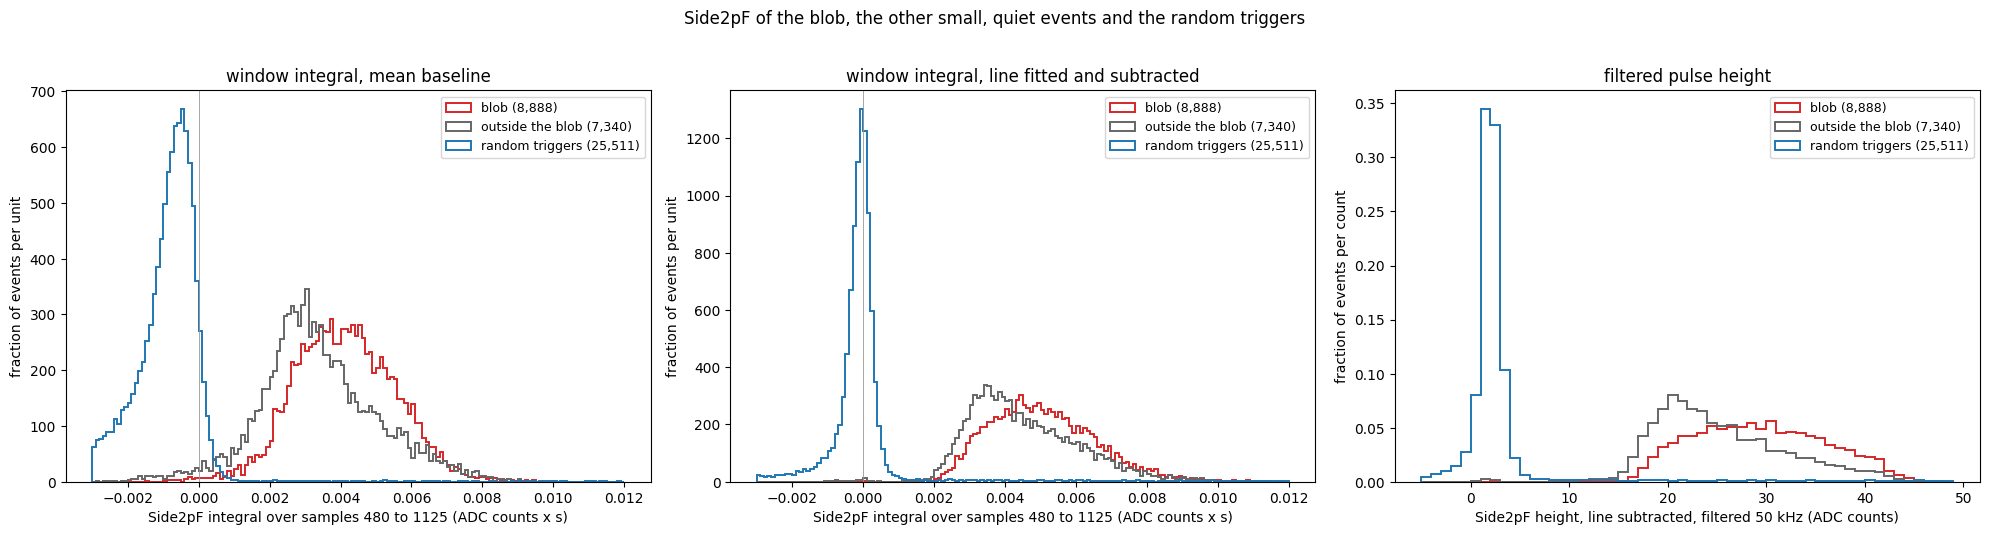

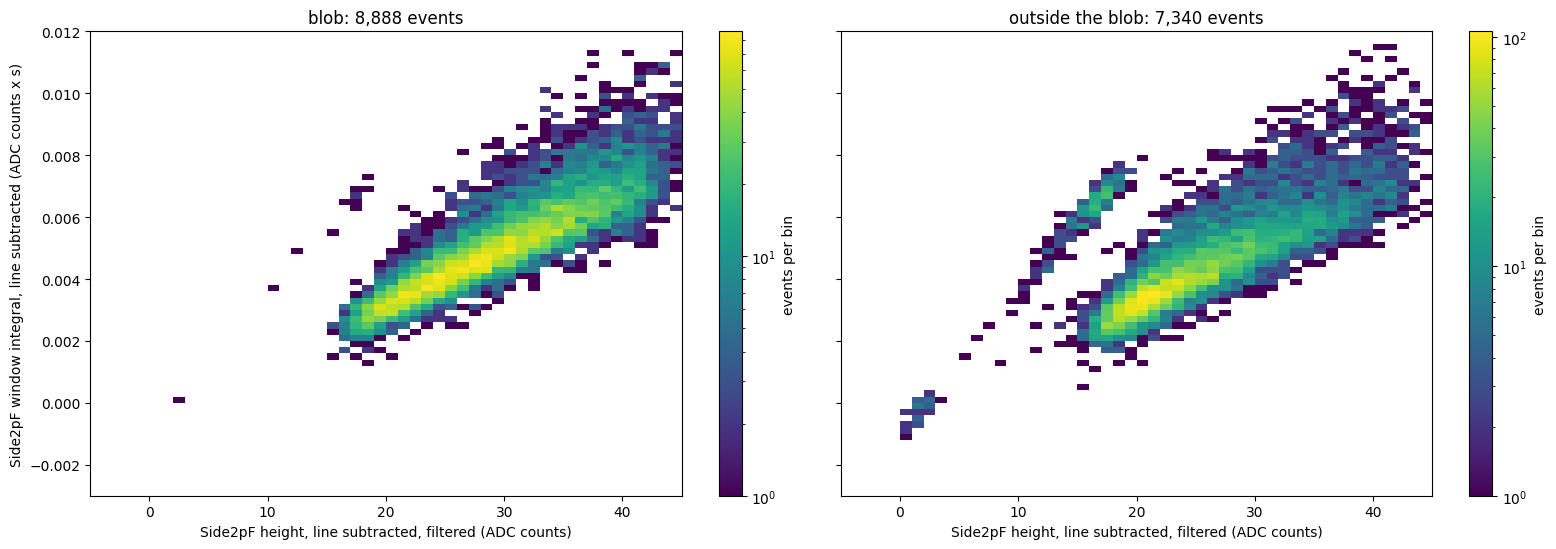

In [11]:
SETS = ((blob, "C3", f"blob ({blob.sum():,})"), (rest, "0.4", f"outside the blob ({rest.sum():,})"),
        (rand & keep, "C0", f"random triggers ({(rand & keep).sum():,})"))
BINS_W = np.linspace(-0.003, 0.012, 151)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
for ax, q, title in ((axes[0], integral_w[:, F], "window integral, mean baseline"),
                     (axes[1], integral_wl[:, F], "window integral, line fitted and subtracted")):
    for m, c, lab in SETS:
        ax.hist(q[m], bins=BINS_W, histtype="step", density=True, color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel(f"Side2pF integral over samples {WIN[0]} to {WIN[1]} (ADC counts x s)")
    ax.set_ylabel("fraction of events per unit")
    ax.set_title(title)
    ax.legend(fontsize=9)
for m, c, lab in SETS:
    axes[2].hist(height_fl[m, F], bins=np.arange(-5, 50, 1), histtype="step", density=True, color=c, linewidth=1.4, label=lab)
axes[2].set_xlabel("Side2pF height, line subtracted, filtered 50 kHz (ADC counts)")
axes[2].set_ylabel("fraction of events per count")
axes[2].set_title("filtered pulse height")
axes[2].legend(fontsize=9)
fig.suptitle("Side2pF of the blob, the other small, quiet events and the random triggers", y=1.02)
fig.tight_layout()
plt.show()

# the line-subtracted window integral against the filtered height: one pulse shape gives one line through the origin
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharex=True, sharey=True)
for ax, m, title in ((axes[0], blob, "blob"), (axes[1], rest, "outside the blob")):
    h = ax.hist2d(height_fl[m, F], integral_wl[m, F], bins=[50, 75], range=[(-5, 45), (-0.003, 0.012)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.set_xlabel("Side2pF height, line subtracted, filtered (ADC counts)")
    ax.set_title(f"{title}: {m.sum():,} events")
    fig.colorbar(h[3], ax=ax, label="events per bin")
axes[0].set_ylabel("Side2pF window integral, line subtracted (ADC counts x s)")
fig.tight_layout()
plt.show()

### The sum of the inner channels

The line-subtracted window integral (`integral_wl`, samples 480 to 1125) summed over the four **inner** channels, `C`, `D`, `E` and `F` (the three sectors and the centre disc), leaving out the two outer rings `A` and `B`. The channels are summed with equal weights, in ADC counts x s, uncalibrated. The blob, the other small, quiet events and the random triggers, each normalised to its number of events; then the sum against the Side2pF filtered height.

              blob: C+D+E+F window integral, line subtracted, 10/50/90 %: 0.0097  0.0146  0.0200
  outside the blob: C+D+E+F window integral, line subtracted, 10/50/90 %: 0.0083  0.0127  0.0199
   random triggers: C+D+E+F window integral, line subtracted, 10/50/90 %: -0.0415  -0.0004  0.0031


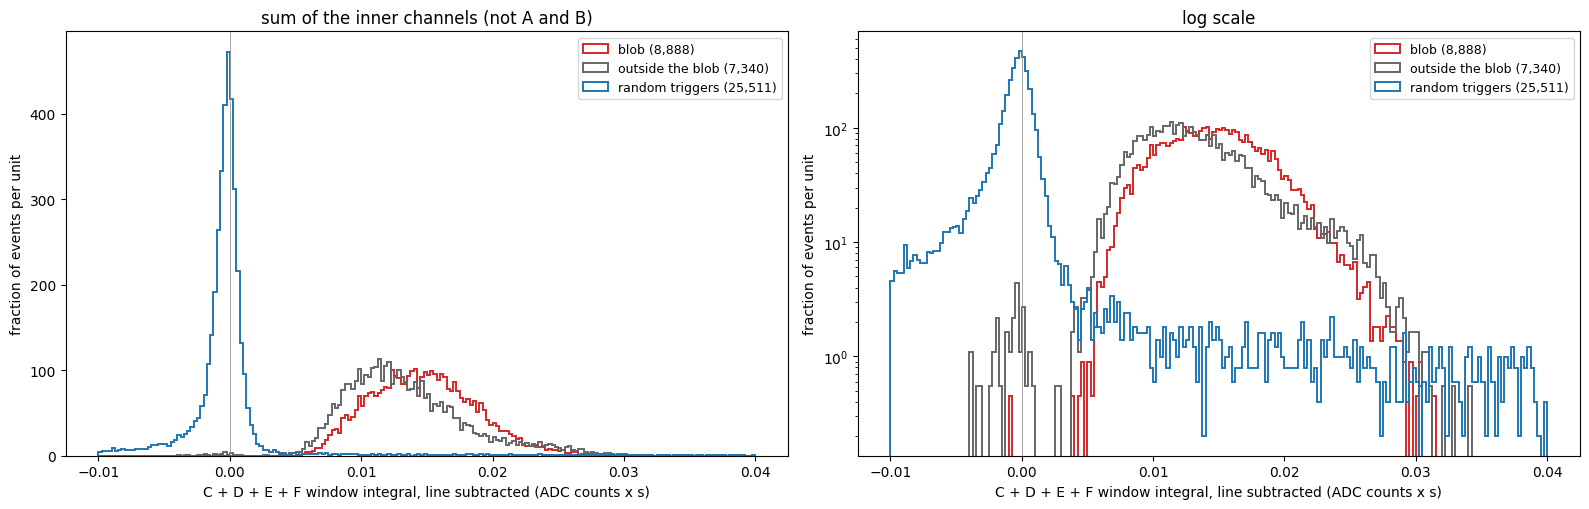

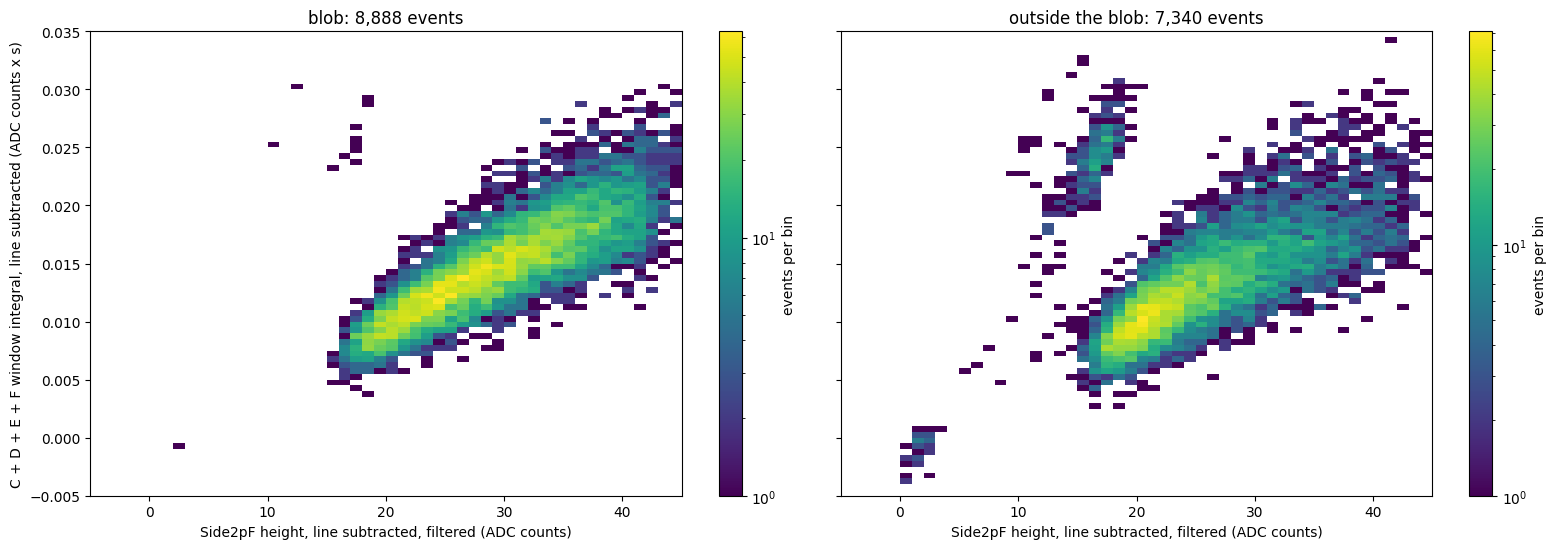

In [12]:
INNER = [LETTERS.index(k) for k in "CDEF"]
inner = integral_wl[:, INNER].sum(axis=1)
for name, m in (("blob", blob), ("outside the blob", rest), ("random triggers", rand & keep)):
    p = np.percentile(inner[m], [10, 50, 90])
    print(f"{name:>18}: C+D+E+F window integral, line subtracted, 10/50/90 %: " + "  ".join(f"{v:.4f}" for v in p))

BINS_S = np.linspace(-0.01, 0.04, 201)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, log in zip(axes, (False, True)):
    for m, c, lab in SETS:
        ax.hist(inner[m], bins=BINS_S, histtype="step", density=True, color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("C + D + E + F window integral, line subtracted (ADC counts x s)")
    ax.set_ylabel("fraction of events per unit")
    if log:
        ax.set_yscale("log")
    ax.set_title("log scale" if log else "sum of the inner channels (not A and B)")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharex=True, sharey=True)
for ax, m, title in ((axes[0], blob, "blob"), (axes[1], rest, "outside the blob")):
    h = ax.hist2d(height_fl[m, F], inner[m], bins=[50, 80], range=[(-5, 45), (-0.005, 0.035)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.set_xlabel("Side2pF height, line subtracted, filtered (ADC counts)")
    ax.set_title(f"{title}: {m.sum():,} events")
    fig.colorbar(h[3], ax=ax, label="events per bin")
axes[0].set_ylabel("C + D + E + F window integral, line subtracted (ADC counts x s)")
fig.tight_layout()
plt.show()

### The sum of all six channels

The same with all six channels, the outer rings `A` and `B` included: the line-subtracted window integral (`integral_wl`) summed over `A` to `F`, equal weights, uncalibrated. Next to it, the inner sum of the section above against the outer sum (`A` + `B`), to see how the two parts share the signal.

              blob: A+...+F window integral, line subtracted, 10/50/90 %: 0.0133  0.0202  0.0283;  median share of A+B: 0.28
  outside the blob: A+...+F window integral, line subtracted, 10/50/90 %: 0.0114  0.0178  0.0295;  median share of A+B: 0.28
   random triggers: A+...+F window integral, line subtracted, 10/50/90 %: -0.0782  -0.0007  0.0030;  median share of A+B: 0.39


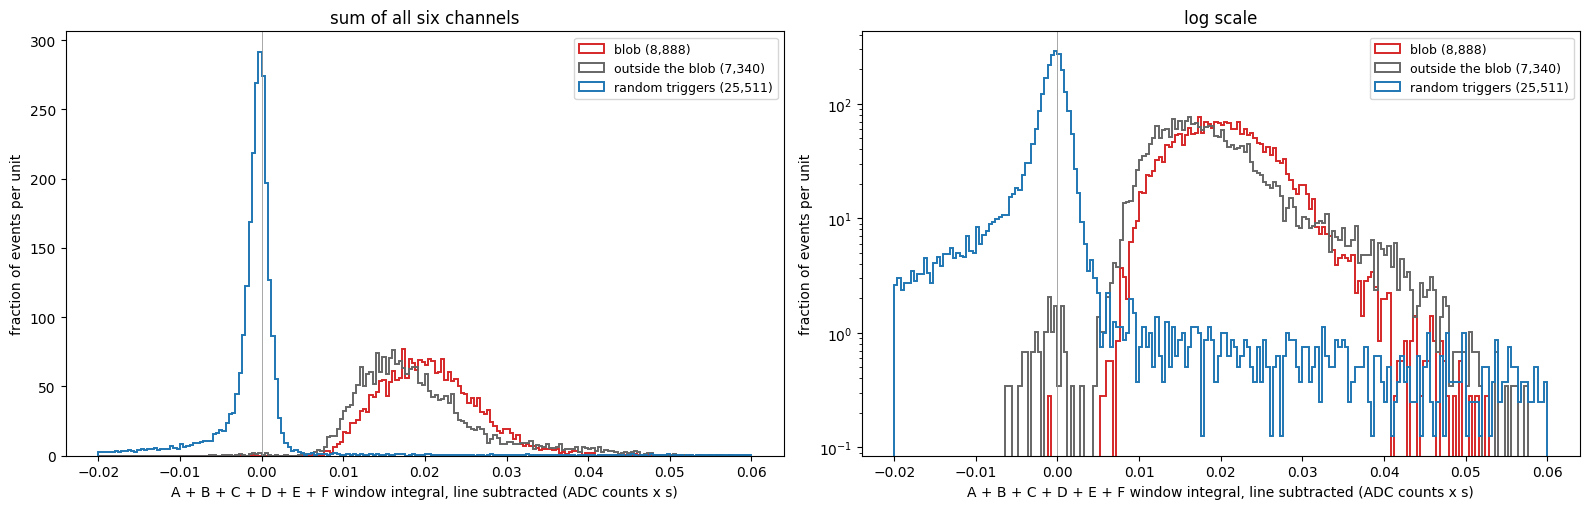

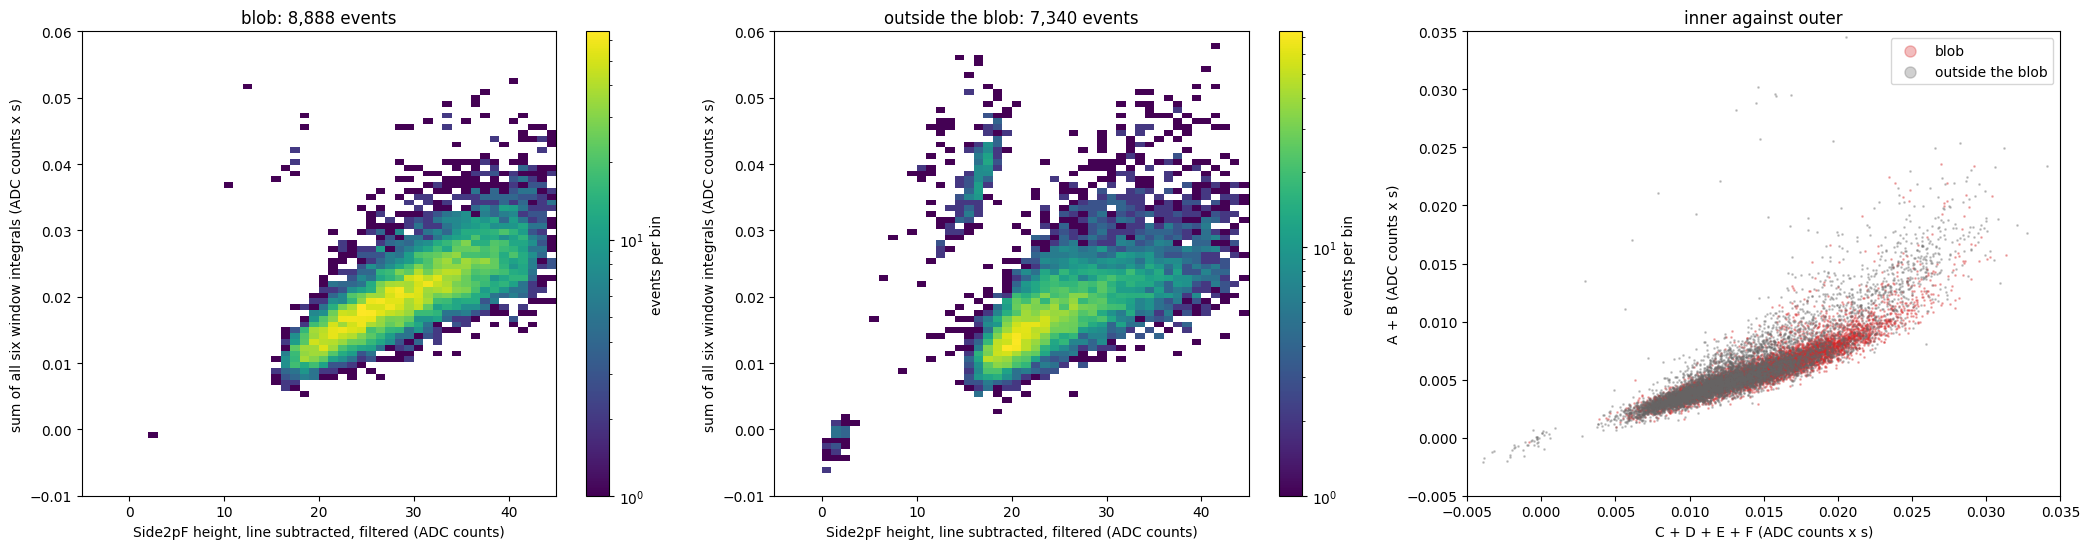

In [13]:
total_w = integral_wl.sum(axis=1)
outer = integral_wl[:, [LETTERS.index("A"), LETTERS.index("B")]].sum(axis=1)
for name, m in (("blob", blob), ("outside the blob", rest), ("random triggers", rand & keep)):
    p = np.percentile(total_w[m], [10, 50, 90])
    print(f"{name:>18}: A+...+F window integral, line subtracted, 10/50/90 %: " + "  ".join(f"{v:.4f}" for v in p)
          + f";  median share of A+B: {np.median(outer[m] / np.where(total_w[m] != 0, total_w[m], np.nan)):.2f}")

BINS_T = np.linspace(-0.02, 0.06, 201)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, log in zip(axes, (False, True)):
    for m, c, lab in SETS:
        ax.hist(total_w[m], bins=BINS_T, histtype="step", density=True, color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("A + B + C + D + E + F window integral, line subtracted (ADC counts x s)")
    ax.set_ylabel("fraction of events per unit")
    if log:
        ax.set_yscale("log")
    ax.set_title("log scale" if log else "sum of all six channels")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
for ax, m, title in ((axes[0], blob, "blob"), (axes[1], rest, "outside the blob")):
    h = ax.hist2d(height_fl[m, F], total_w[m], bins=[50, 80], range=[(-5, 45), (-0.01, 0.06)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    ax.set_xlabel("Side2pF height, line subtracted, filtered (ADC counts)")
    ax.set_ylabel("sum of all six window integrals (ADC counts x s)")
    ax.set_title(f"{title}: {m.sum():,} events")
    fig.colorbar(h[3], ax=ax, label="events per bin")
for m, c, lab in ((blob, "C3", "blob"), (rest, "0.4", "outside the blob")):
    axes[2].scatter(inner[m], outer[m], s=1, alpha=0.3, color=c, label=lab, rasterized=True)
axes[2].set_xlim(-0.005, 0.035); axes[2].set_ylim(-0.005, 0.035)
axes[2].set_xlabel("C + D + E + F (ADC counts x s)")
axes[2].set_ylabel("A + B (ADC counts x s)")
axes[2].set_title("inner against outer")
axes[2].legend(markerscale=8)
fig.tight_layout()
plt.show()

**What this shows, and what is not done.** The position distribution, from the delays, of the events that are quiet in every channel and small in every channel. Not done: millimetres, the offsets and the scale (both set so that the large circle of events is centred and is the face: an assumption, not derived), filtered times (the 20 % times are of the raw traces and are noisy for pulses of tens of counts), and a check of whether the two high-activity spots of the large events are the same objects as any feature here.